## Model Evaluation
In this notebook, I will look into the classifications made by the model in the validation split, understand possible problems of my models, make it more grey-box and compare them and choose the best possible configurations for this architecture to implement as a final version.

## Importing Data

In [1]:
from pathlib import Path
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Model Loading

In [14]:
import sys
import torch

sys.path.append("../src")

from unet import UNet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet(in_channels=3, num_classes=8).to(device)

checkpoint = torch.load(
    checkpoint_paths["Best Checkpoint"],
    map_location=device,
    weights_only=False
)

print("Device:", device)
print(checkpoint.keys())

Device: cpu
dict_keys(['epoch', 'model', 'optimizer', 'val_miou', 'class_weights'])


In [15]:
model.load_state_dict(checkpoint["model"])
model.eval()

print("Model loaded successfully")
print("Best epoch:", checkpoint["epoch"])
print("Validation mIoU:", checkpoint["val_miou"])

Model loaded successfully
Best epoch: 19
Validation mIoU: 0.30812967


In [16]:
from dataset import LandCoverDataset
from torch.utils.data import DataLoader

pairs_df = pd.read_csv("../results/tables/split_manifest.csv")

val_pairs = pairs_df[pairs_df["split"] == "validation"]

val_dataset = LandCoverDataset(val_pairs)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Validation images:", len(val_dataset))

Validation images: 275


## Result Loading

In [7]:
RESULTS_DIR = Path("../results/models")
BACKUP_DIR = RESULTS_DIR / "fontys_backup"

checkpoint_paths = {
    "Second Attempt": BACKUP_DIR / "unet_baseline_experiment_2nd_try.pth",
    "Third Attempt": BACKUP_DIR / "unet_baseline_experiment_3nd_try.pth",
    "Best Checkpoint": BACKUP_DIR / "unet_baseline_experiment_best.pth"
}

history_path = RESULTS_DIR / "baseline_experiment_history.csv"
per_class_path = RESULTS_DIR / "baseline_experiment_best_validation_per_class.csv"

for name, path in checkpoint_paths.items():
    print(name, path.exists())

print("Training History:", history_path.exists())
print("Per-Class Results:", per_class_path.exists())

Second Attempt True
Third Attempt True
Best Checkpoint True
Training History: True
Per-Class Results: True


In [11]:
history = pd.read_csv(history_path)
per_class_results = pd.read_csv(per_class_path)

print("Recorded epochs:", len(history))

display(history.head())
display(history.tail())

class_names = [
    "Bareland",
    "Rangeland",
    "Developed Space",
    "Road",
    "Tree",
    "Water",
    "Agriculture Land",
    "Building"
]

per_class_results["Class"] = class_names

display(per_class_results)

Recorded epochs: 24


,epoch,train_loss,train_miou,train_dice,val_loss,val_miou,val_dice
0,1,1.662827,0.165248,0.261575,1.799157,0.148944,0.239686
1,2,1.526989,0.209410,0.327450,1.677520,0.230538,0.357314
2,3,1.484283,0.222823,0.346803,1.958417,0.158485,0.256198
3,4,1.451243,0.237448,0.367768,1.792960,0.202264,0.317091
4,5,1.440974,0.241133,0.370875,1.676383,0.208062,0.327895


,epoch,train_loss,train_miou,train_dice,val_loss,val_miou,val_dice
19,20,1.267316,0.307413,0.454866,1.603716,0.275341,0.409522
20,21,1.269272,0.309798,0.457310,1.579612,0.277719,0.415651
21,22,1.246234,0.314948,0.460675,1.412352,0.298312,0.442293
22,23,1.245967,0.314313,0.462161,1.591983,0.241505,0.374548
23,24,1.222798,0.323491,0.473277,1.438649,0.283464,0.426437


,Class ID,IoU,Dice,Class
0,0,0.031279,0.060662,Bareland
1,1,0.256996,0.408905,Rangeland
2,2,0.306808,0.469554,Developed Space
3,3,0.233443,0.378522,Road
4,4,0.455161,0.625582,Tree
5,5,0.252007,0.402565,Water
6,6,0.408584,0.580134,Agriculture Land
7,7,0.520760,0.684868,Building


### Results Explained
As seen above, it is quite visual the fact that the training loss got smaller and smaller throughout the training, however I can not yet conclude that the learning is healthy or not. The mIoU improves and in validation the same thing happens. I cannot conclude that the learning is healthy, that there is no overfitting, thats why I will look into more detail about this in the next cells.
Every class is already classified, however as it was seen in **01_EDA_loading.ipynb** bareland is really tricky to classify with only 3% IoU, but the other smaller classes like water are having a 25% IoU, so Weighted Cross Entropy is working quite well in this case.

## Learning Curves Analysis
I will analyse the learning curves to understand the performance of the model, how stable it is and if it is overfitting/underfitting and generalizing well.

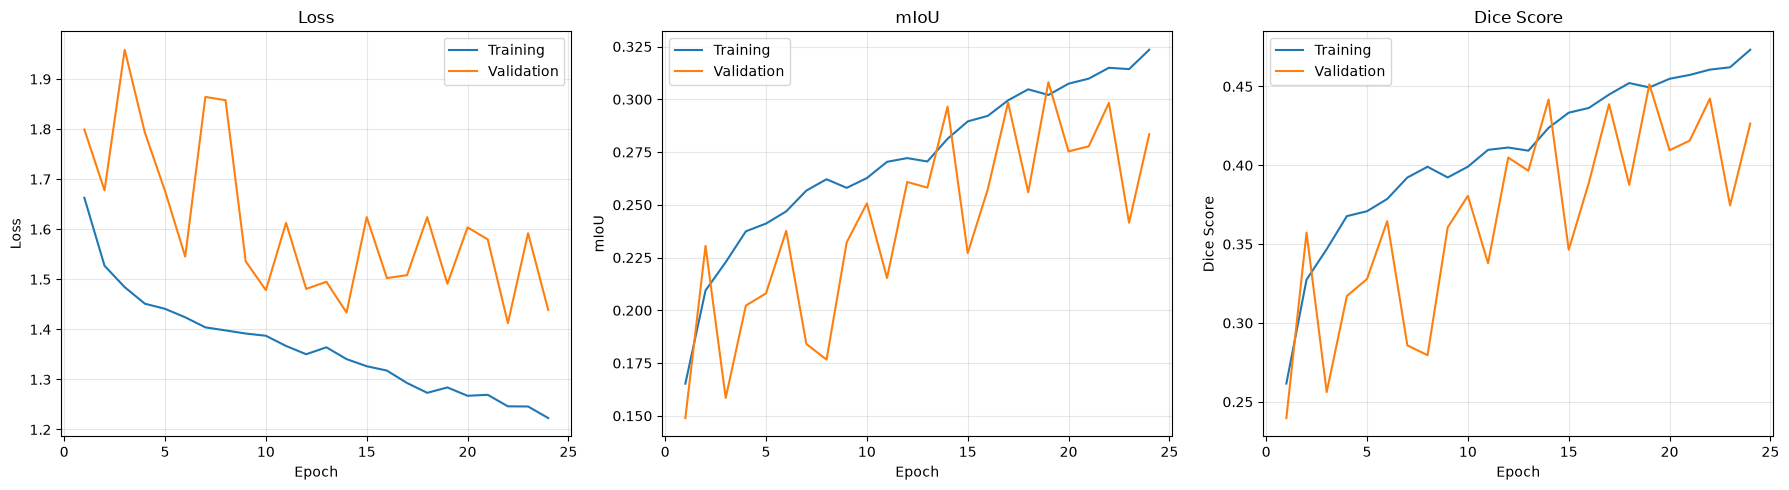

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ["loss", "miou", "dice"]
titles = ["Loss", "mIoU", "Dice Score"]

for ax, metric, title in zip(axes, metrics, titles):

    ax.plot(history["epoch"], history[f"train_{metric}"],
            label="Training")

    ax.plot(history["epoch"], history[f"val_{metric}"],
            label="Validation")

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

It is quite clear that the model is learning, however in the training bits the learning is quite healthy and in validation there is no stability whatsoever. This can be because of a learning rate too high, batch size or difficulty generalizing.
It is not clear whether the model is overfitted/underfitted, because it is still following the trend, just unstable. 
Early stopping is also a problem, because I never got to convergence, neither a plateau, so this also needs a change.

-Learning Rate Change

-Early Stopping to Small

-Batch Size changed

-Implementation of Learning Rate Scheduler.


## Per-Class Performance

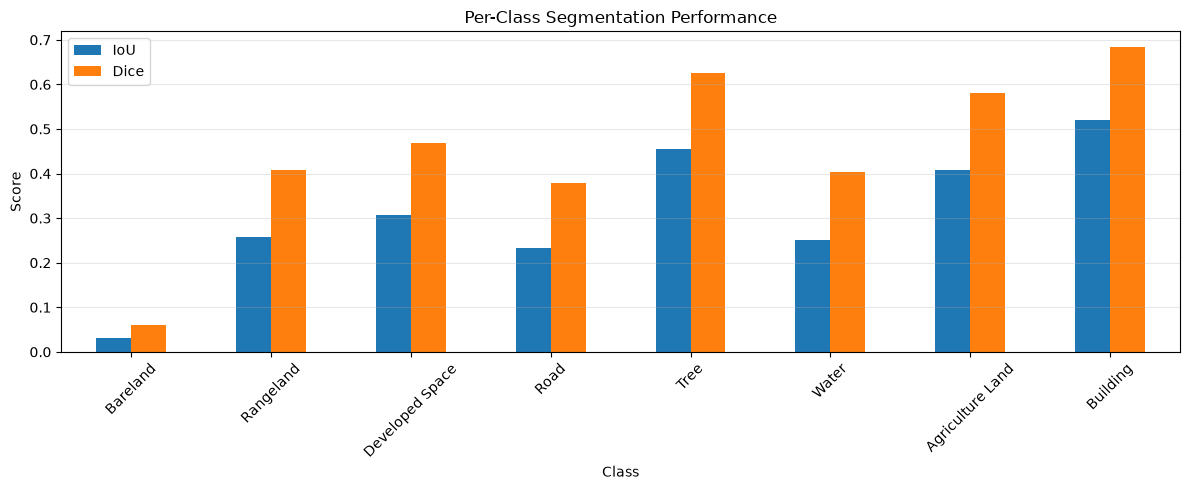

In [ ]:
per_class_results.plot(
    x="Class",
    y=["IoU", "Dice"],
    kind="bar",
    figsize=(12, 5)
)

plt.title("Per-Class Segmentation Performance")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

It is possible to conclude that due to the fact that bareland has too little coverage it performs the worst. Classes like tree and building are quite good, since they had more example and are quite different from the others, same as agriculture land. Rangeland and developed space might have a problem, since they are quite ambiguous in the labelling to tree, building, road and agriculture land, making it harder to make the model perform better. Road, tree and water, normally are smaller bits and this can  be affected due to the resize as it looses quality on the images and the model cannot comprehend this classes.

**Potential improvements:**

-Class weight optimization.

-Alternative loss functions.

-Higher image resolution.

-Transfer Learning.

## Confusion Matrix

In [17]:
confusion_matrix = torch.zeros((8, 8), dtype=torch.int64)

with torch.no_grad():
    for images, masks in tqdm(val_loader):

        logits = model(images.to(device))
        predictions = logits.argmax(dim=1).cpu()

        valid = masks != 255

        indices = 8 * masks[valid] + predictions[valid]

        confusion_matrix += torch.bincount(
            indices, minlength=64
        ).reshape(8, 8)

print(confusion_matrix)

100%|██████████| 35/35 [00:51<00:00,  1.48s/it]

tensor([[  38118,  193568,  239565,   17710,   75927,    2553,  542543,   54759],
        [   5989, 1412795,  359624,   22750, 1010950,   26106,  506854,  127317],
        [  15994,  589379, 1609132,  143177,  171790,   11667,  260515,  756061],
        [   2132,   72064,  342965,  262917,   20889,    6572,   42232,  142619],
        [    336,  512379,   82145,    2973, 1970789,    6201,  213080,   17768],
        [   8159,  120927,   78359,   11072,   27494,  213768,  265768,   25364],
        [  19711,  434249,   62035,    9276,  168115,   39311, 1776444,    4351],
        [   1274,  102318,  522386,   26908,   49050,    4906,    3277, 1997626]])


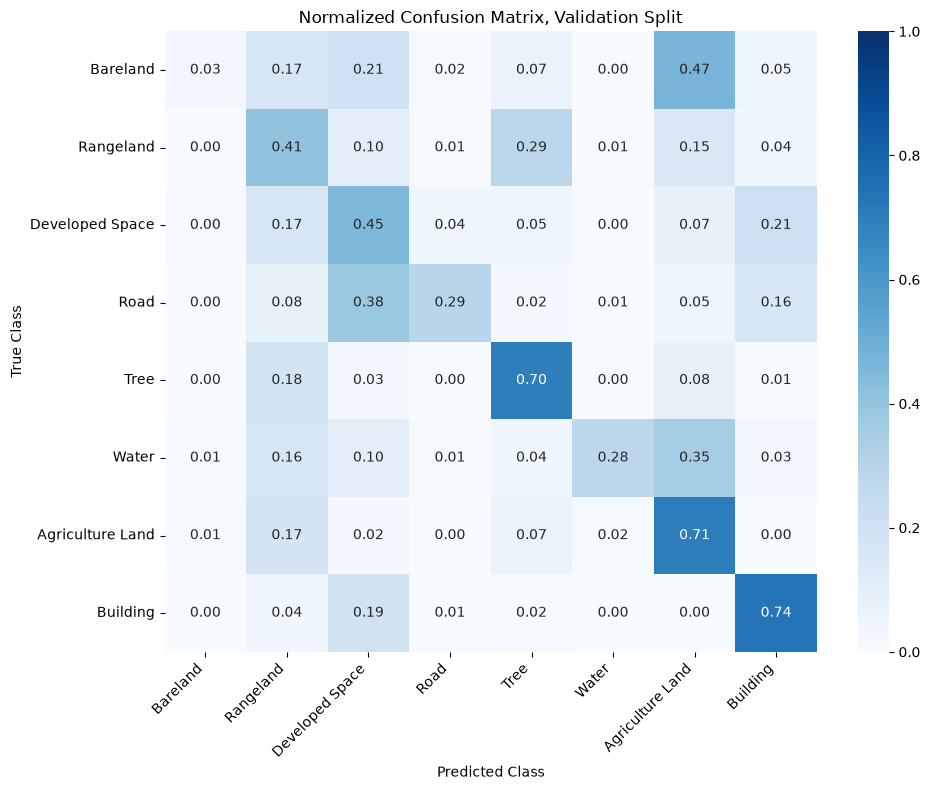

In [ ]:
cm_normalized = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1
)

plt.title("Normalized Confusion Matrix, Validation Split")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Confusion Matrix Analysis

The confusion matrix reveals specific misclassification patterns between land-cover classes.
Bareland and Water are frequently misclassified as Agriculture Land, while Road is frequently confused with Developed Space.

The model also struggles to distinguish between vegetation classes and between different urban surfaces. These patterns suggest potential limitations in feature extraction and class discrimination. Visual prediction analysis is required to better understand the causes of these errors.

## Precision and Recall Analysis

In [21]:
tp = np.diag(cm)

precision = tp / cm.sum(axis=0)
recall = tp / cm.sum(axis=1)

precision_recall = pd.DataFrame({
    "Class": class_names,
    "Precision": precision,
    "Recall": recall
})

display(precision_recall)

,Class,Precision,Recall
0,Bareland,0.415623,0.032727
1,Rangeland,0.410974,0.406866
2,Developed Space,0.488176,0.452294
3,Road,0.529239,0.294621
4,Tree,0.563887,0.702431
5,Water,0.687171,0.284678
6,Agriculture Land,0.491993,0.706763
7,Building,0.639063,0.737745


There are significant differences between precision and recall across classes. Bareland, Water and Road are underpredicted, while others are overpredicted.
Water achieves the highest precision, but lowest recall, indicating difficulties in identifying all pixels.
These results showcase some difficulties classifying, even after Weighted Cross Entropy.

## Actual vs Predicted Class

,Class,Actual,Predicted,Difference
0,Bareland,0.065197,0.005134,-0.060063
1,Rangeland,0.194367,0.192425,-0.001943
2,Developed Space,0.199144,0.184506,-0.014638
3,Road,0.049952,0.027808,-0.022144
4,Tree,0.157048,0.195634,0.038586
5,Water,0.042032,0.017413,-0.024619
6,Agriculture Land,0.140693,0.202110,0.061417
7,Building,0.151567,0.174971,0.023404


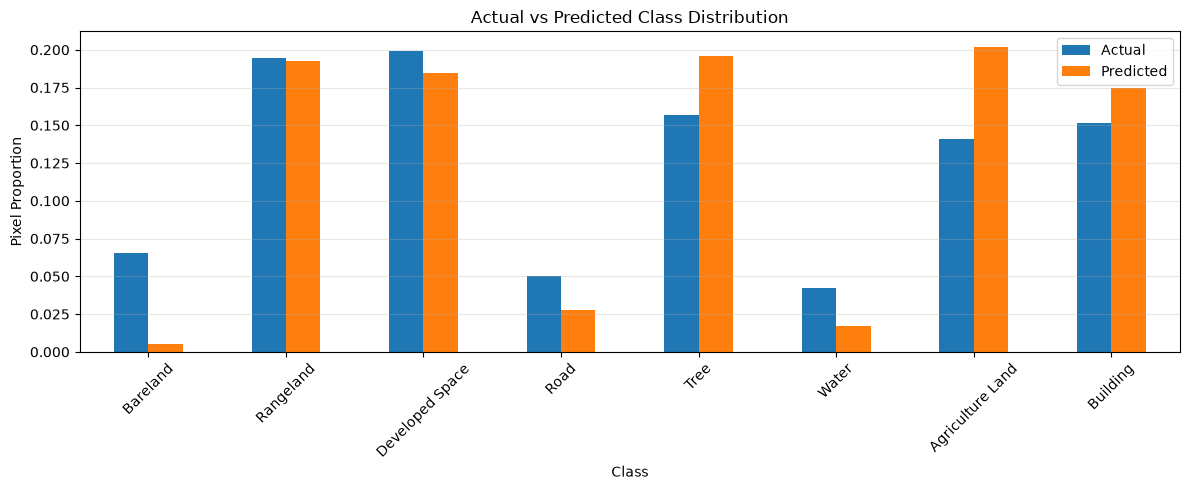

In [22]:
actual_counts = cm.sum(axis=1)
predicted_counts = cm.sum(axis=0)

distribution = pd.DataFrame({
    "Class": class_names,
    "Actual": actual_counts / actual_counts.sum(),
    "Predicted": predicted_counts / predicted_counts.sum()
})

distribution["Difference"] = (
    distribution["Predicted"] - distribution["Actual"]
)

display(distribution)

# Visualization
distribution.plot(
    x="Class",
    y=["Actual", "Predicted"],
    kind="bar",
    figsize=(12, 5)
)

plt.title("Actual vs Predicted Class Distribution")
plt.ylabel("Pixel Proportion")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

There are tendencies to look into some classes and predict them more than others. This is due to training examples and class coverage around different splits.

## Visual Prediction and Error

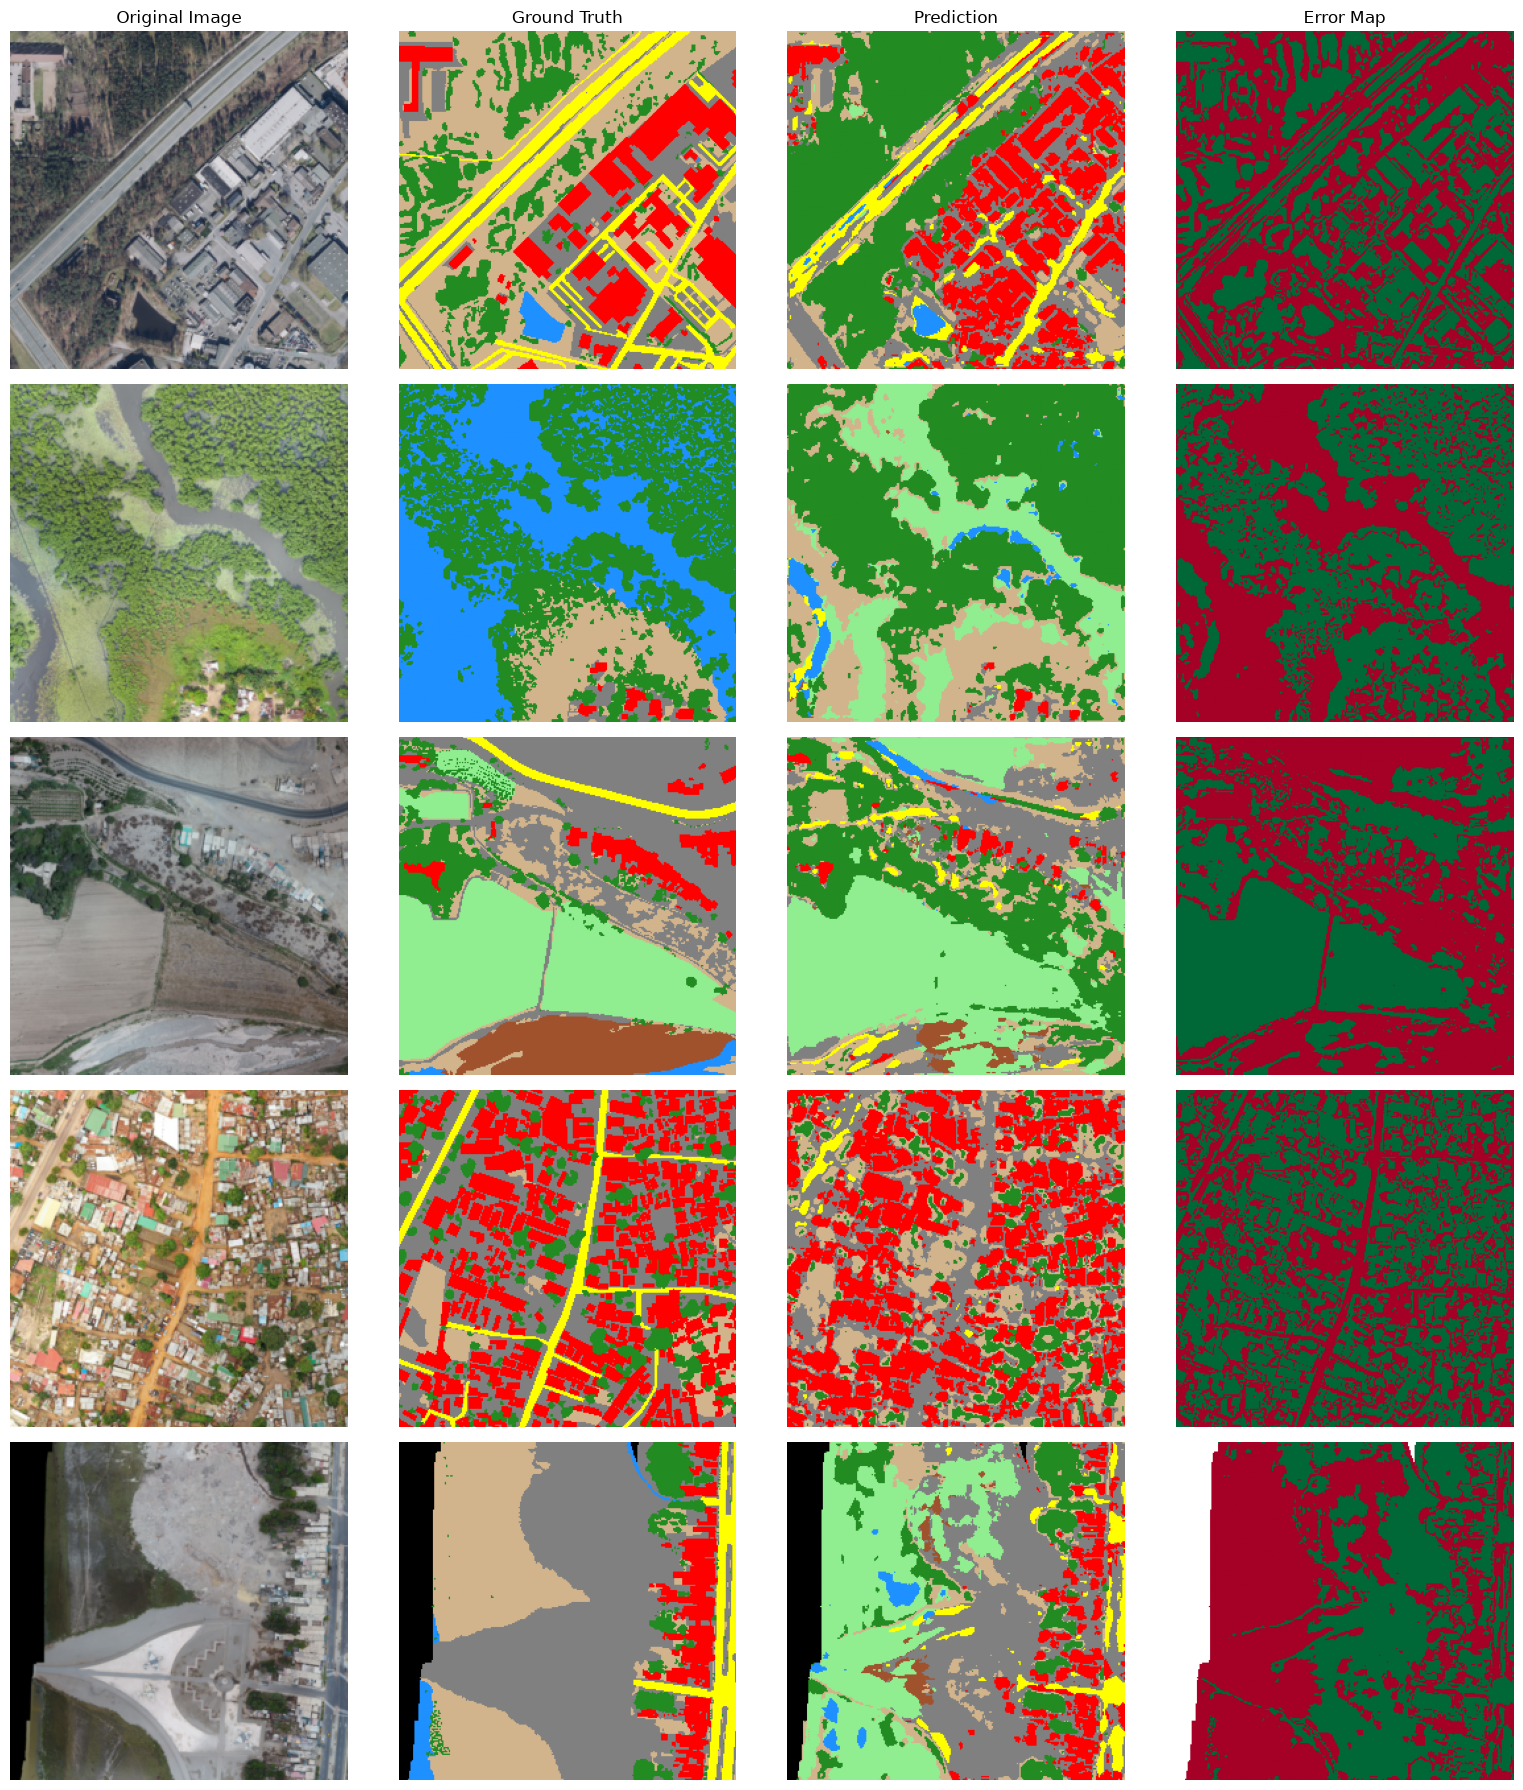

In [23]:
from matplotlib.colors import ListedColormap

colors = [
    "#A0522D",  # Bareland
    "#D2B48C",  # Rangeland
    "#808080",  # Developed Space
    "#FFFF00",  # Road
    "#228B22",  # Tree
    "#1E90FF",  # Water
    "#90EE90",  # Agriculture Land
    "#FF0000"   # Building
]

cmap = ListedColormap(colors)
cmap.set_bad("black")

examples = val_pairs.sample(5, random_state=42)
example_dataset = LandCoverDataset(examples)

fig, axes = plt.subplots(5, 4, figsize=(16, 18))

model.eval()

with torch.no_grad():
    for i, (image, mask) in enumerate(example_dataset):

        logits = model(image.unsqueeze(0).to(device))
        prediction = logits.argmax(dim=1).squeeze(0).cpu().numpy()

        image = image.permute(1, 2, 0).numpy()
        mask = mask.numpy()

        valid = mask != 255
        errors = prediction != mask

        axes[i, 0].imshow(image)
        axes[i, 1].imshow(
            np.ma.masked_where(~valid, mask),
            cmap=cmap, vmin=0, vmax=7
        )
        axes[i, 2].imshow(
            np.ma.masked_where(~valid, prediction),
            cmap=cmap, vmin=0, vmax=7
        )
        axes[i, 3].imshow(
            np.ma.masked_where(~valid, errors),
            cmap="RdYlGn_r", vmin=0, vmax=1
        )

        for ax in axes[i]:
            ax.axis("off")

titles = ["Original Image", "Ground Truth", "Prediction", "Error Map"]

for ax, title in zip(axes[0], titles):
    ax.set_title(title)

plt.tight_layout()
plt.show()

Observing the images, even though, the results aren't quite well, it is possible to see that the model can somewhat create a decent classification. It makes some mistakes, but, overall in the big picture it is not that far from labelled images. There are some problems around shapes, textures and shadows. Maybe this is due to the encoder not being pre-trained and some ambiguosity around labels.